# [Lab Session 2](otsu.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

In [2]:
imgf = (plt.imread('data/NIH3T3/im/dna-0.png'))

**[Task 1.2.]()** Quantify the image into 256 bins:

In [3]:
img8 = (imgf * 255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

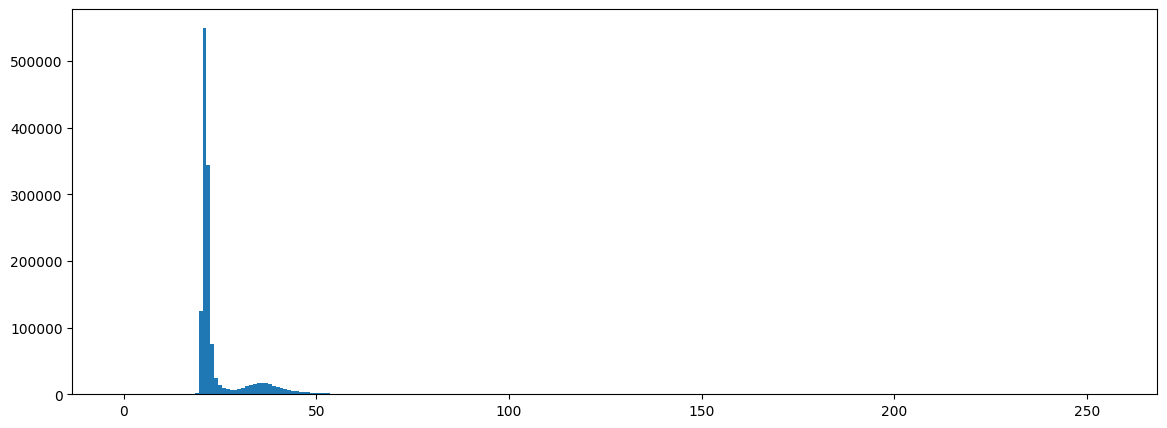

In [5]:
x = np.zeros(256)
for i in range(256):
    x[i] = np.sum(img8 == i)

plt.figure(figsize=(14,5))
plt.bar(range(256), x, width = 1)
plt.show()

Show the computed histogram:

In [ ]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

**[Task 1.4.]()** Implement the method of Otsu:

In [25]:
variances = []
bins = np.arange(256)
total = np.sum(x)
min_variance = float('inf')
best_threshold = 0

for T in range(1,256):
    n1 = np.sum(x[:T])
    n2 = np.sum(x[T:])
    if n1 == 0 or n2 == 0:
        continue
    w1 = n1 / total
    w2 = n2/ total
    mean1 = np.sum(bins[:T] *x[:T]) / n1
    mean2 = np.sum(bins[T:] * x[T:]) / n2
    var1 = np.sum(((bins[:T] - mean1) ** 2) * x[:T]) / n1
    var2 = np.sum(((bins[T:] - mean2) ** 2) * x[T:]) / n2
    current_variance = w1 * var1 + w2 * var2
    variances.append(current_variance)

    if current_variance < min_variance:
        min_variance = current_variance
        best_threshold = T



print(best_threshold)



31


**[Task 1.5.]()** Perform Otsu thresholding:

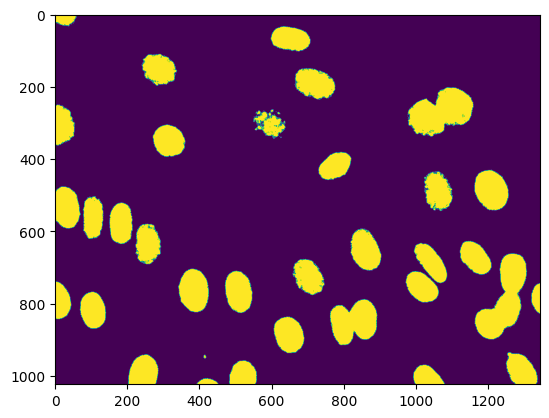

In [27]:
img_out = img8 >= best_threshold
plt.imshow(img_out)

**[Task 1.6.]()** Compute the Dice coefficient:

0.8943783223933183


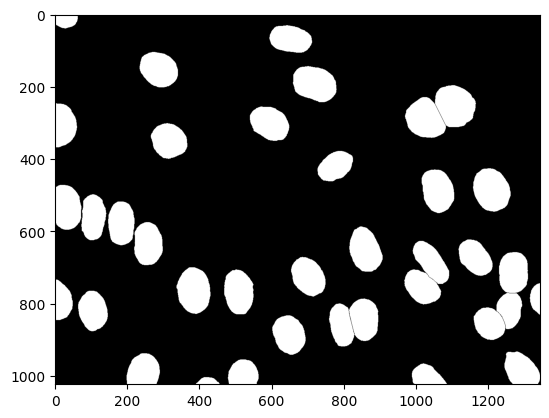

In [28]:
ground = plt.imread('data/NIH3T3/gt/0.png')
plt.imshow(ground, cmap = 'gray')
H = img_out
G = ground


dice_GH = (2 * (G * H).sum()/(G.sum() + H.sum()))
print(dice_GH)